# Spaceship Titanic | Notebook 05: Advanced Experiments and Model Interpretation

**Project stage:** Passenger-group features, controlled CatBoost tuning, validation design, and explanation of predictions.  
**Target:** `Transported` (binary classification).  
**Baseline:** 13 predictors; CatBoost with 500 iterations, depth 6, learning rate 0.05.  

This notebook reproduces experiments CAT-003 through CAT-008 while preserving the original code and saved results. The sections are sequential: run cells from the top after loading `train.csv` and `test.csv` from the project folder. Code comments describe operations; Markdown describes analytical reasoning and findings.

**Evaluation caution:** All cross-validation experiments below use only the 80% development-training subset, not the full labelled dataset. Previous Kaggle public leaderboard score of **80.383%** is a separate official score, not a CV result.

In [1]:
# ============================================================
# STEP 19B: IMPORT LIBRARIES AND LOAD DATA
# ============================================================

# Import pandas for data manipulation.
import pandas as pd

# Import NumPy for numerical operations.
import numpy as np

# Import Path for file management.
from pathlib import Path

# Define our project directory.
# Support running from either the project root or its notebooks/ folder.
project_root = Path.cwd()
if not (project_root / "train.csv").exists():
    project_root = project_root.parent

if not (project_root / "train.csv").exists():
    raise FileNotFoundError(
        "Cannot find train.csv. Run this notebook from the spaceship-titanic "
        "project directory (or its notebooks subfolder)."
    )

# Load the original competition datasets.
train_df = pd.read_csv(project_root / "train.csv")
test_df = pd.read_csv(project_root / "test.csv")

# Display dataset dimensions.
print("Training dataset:", train_df.shape)
print("Test dataset:", test_df.shape)

Training dataset: (8693, 14)
Test dataset: (4277, 13)


## Part A — Passenger-Group Feature Engineering (CAT-003)

### 1. Read Data and Extract Group Identifiers

`PassengerId` includes a group identifier and passenger number (for example, `0003_02`). We extract both components and retain the original dataset as separate copies. The group identifier itself is not used as a predictive feature in CAT-003.

In [2]:
# ============================================================
# STEP 19C: EXTRACT PASSENGER GROUP INFORMATION
# ============================================================

# Create copies so that the original datasets remain unchanged.
train_groups = train_df.copy()
test_groups = test_df.copy()

# Extract the group identifier from PassengerId.
# Example: "0003_02" becomes "0003".
train_groups["PassengerGroup"] = (
    train_groups["PassengerId"].str.split("_").str[0]
)

test_groups["PassengerGroup"] = (
    test_groups["PassengerId"].str.split("_").str[0]
)

# Extract the passenger number.
# Example: "0003_02" becomes 2.
train_groups["PassengerNumber"] = pd.to_numeric(
    train_groups["PassengerId"].str.split("_").str[1],
    errors="coerce"
)

test_groups["PassengerNumber"] = pd.to_numeric(
    test_groups["PassengerId"].str.split("_").str[1],
    errors="coerce"
)

# Display the first ten passengers.
display(
    train_groups[
        [
            "PassengerId",
            "PassengerGroup",
            "PassengerNumber"
        ]
    ].head(10)
)

,PassengerId,PassengerGroup,PassengerNumber
0,0001_01,0001,1
1,0002_01,0002,1
2,0003_01,0003,1
3,0003_02,0003,2
4,0004_01,0004,1
5,0005_01,0005,1
6,0006_01,0006,1
7,0006_02,0006,2
8,0007_01,0007,1
9,0008_01,0008,1


### 2. Create Group-Size Features

Group sizes are counted using identifiers from both the labelled training set and the competition test set. **No test labels are accessed**, but this uses the unlabeled competition test manifest (a transductive assumption). This is appropriate only if the complete passenger manifest is available when making predictions; it would not automatically transfer to a real-world system receiving passengers one at a time.

In [3]:
# ============================================================
# STEP 19D: CALCULATE PASSENGER GROUP SIZE
# ============================================================

# Combine passenger group identifiers from training and test.
# We are combining identifiers only, not target outcomes.
all_groups = pd.concat(
    [
        train_groups["PassengerGroup"],
        test_groups["PassengerGroup"]
    ],
    ignore_index=True
)

# Count how many passengers belong to each group.
group_size_counts = all_groups.value_counts()

# Assign group sizes to training passengers.
train_groups["GroupSize"] = (
    train_groups["PassengerGroup"].map(group_size_counts)
)

# Assign group sizes to test passengers.
test_groups["GroupSize"] = (
    test_groups["PassengerGroup"].map(group_size_counts)
)

# Display the first ten passengers.
display(
    train_groups[
        [
            "PassengerId",
            "PassengerGroup",
            "PassengerNumber",
            "GroupSize"
        ]
    ].head(10)
)

,PassengerId,PassengerGroup,PassengerNumber,GroupSize
0,0001_01,0001,1,1
1,0002_01,0002,1,1
2,0003_01,0003,1,2
3,0003_02,0003,2,2
4,0004_01,0004,1,1
5,0005_01,0005,1,1
6,0006_01,0006,1,2
7,0006_02,0006,2,2
8,0007_01,0007,1,1
9,0008_01,0008,1,3


### 3. Validate Group Features

Check that group identifiers, passenger numbers, and group sizes were extracted successfully. A correct group size must be at least one.

In [4]:
# ============================================================
# STEP 19E: VALIDATE PASSENGER GROUP FEATURES
# ============================================================

# Confirm that no passenger is missing a group identifier.
assert train_groups["PassengerGroup"].notna().all()
assert test_groups["PassengerGroup"].notna().all()

# Confirm that all group sizes are positive.
assert (train_groups["GroupSize"] >= 1).all()
assert (test_groups["GroupSize"] >= 1).all()

# Confirm that all passenger numbers are positive.
assert (train_groups["PassengerNumber"] >= 1).all()
assert (test_groups["PassengerNumber"] >= 1).all()

# Display the group-size distribution for labelled passengers.
print("GROUP SIZE DISTRIBUTION")
print("-" * 50)

print(
    train_groups["GroupSize"]
    .value_counts()
    .sort_index()
)

# Display descriptive statistics for group size.
print("\nGROUP SIZE SUMMARY")
print("-" * 50)

print(train_groups["GroupSize"].describe())

# Display the maximum observed group size.
print(
    "\nMaximum group size:",
    group_size_counts.max()
)

# Display total distinct groups across both manifests.
print(
    "Unique groups across both datasets:",
    group_size_counts.size
)

print("\nAll passenger group feature checks passed!")

GROUP SIZE DISTRIBUTION
--------------------------------------------------
GroupSize
1    4805
2    1682
3    1020
4     412
5     265
6     174
7     231
8     104
Name: count, dtype: int64

GROUP SIZE SUMMARY
--------------------------------------------------
count    8693.000000
mean        2.035546
std         1.596347
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max         8.000000
Name: GroupSize, dtype: float64

Maximum group size: 8
Unique groups across both datasets: 9280

All passenger group feature checks passed!


### 4. Extract Cabin Features

Convert `Cabin` into `CabinDeck`, numeric `CabinNumber`, and `CabinSide` as in the baseline. A failed conversion is kept as numerical missingness instead of fabricating a cabin number.

In [5]:
# ============================================================
# STEP 20A: EXTRACT CABIN FEATURES
# ============================================================

def extract_cabin_features(df):
    """
    Extract the deck, cabin number, and cabin side
    from the original Cabin column.
    """

    # Create a copy to preserve the original dataset.
    df = df.copy()

    # Split Cabin using the "/" separator.
    cabin_parts = df["Cabin"].str.split("/", expand=True)

    # Extract cabin deck.
    df["CabinDeck"] = cabin_parts[0]

    # Convert cabin number into a numerical variable.
    df["CabinNumber"] = pd.to_numeric(
        cabin_parts[1],
        errors="coerce"
    )

    # Extract cabin side.
    df["CabinSide"] = cabin_parts[2]

    # Remove the original Cabin column.
    df = df.drop(columns=["Cabin"])

    return df


# Apply feature extraction to both datasets.
train_groups = extract_cabin_features(train_groups)

test_groups = extract_cabin_features(test_groups)

# Display updated dataset dimensions.
print("Training dataset:", train_groups.shape)
print("Test dataset:", test_groups.shape)

Training dataset: (8693, 19)
Test dataset: (4277, 18)


### 5. Define the CAT-003 Predictor Set

The baseline uses 13 features. CAT-003 adds `GroupSize` and `PassengerNumber` for a total of **15 predictors**. The target and original identifier are excluded from the predictors.

In [6]:
# ============================================================
# STEP 20B: DEFINE THE CAT-003 FEATURE SET
# ============================================================

# Original numerical predictors.
numerical_features = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "CabinNumber"
]

# Original categorical predictors.
categorical_features = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "VIP",
    "CabinDeck",
    "CabinSide"
]

# New passenger-group predictors.
group_features = [
    "GroupSize",
    "PassengerNumber"
]

# Combine the original predictors and new group features.
selected_features = (
    numerical_features
    + categorical_features
    + group_features
)

# Select the training predictors.
X = train_groups[selected_features].copy()

# Select the classification target.
y = train_groups["Transported"].copy()

# Select Kaggle test predictors.
X_test = test_groups[selected_features].copy()

# Display dataset dimensions.
print("Training features:", X.shape)
print("Target:", y.shape)
print("Test features:", X_test.shape)

print("Total predictors:", len(selected_features))

Training features: (8693, 15)
Target: (8693,)
Test features: (4277, 15)
Total predictors: 15


### 6. Reproduce the Original Development Split

Use the same stratified 80/20 train/validation split (`random_state=42`) to make experiments comparable. The following 5-fold CV fits the model on subsets of the 80% development-training split (6,954 rows).

In [7]:
# ============================================================
# STEP 20C: REPRODUCE ORIGINAL TRAINING-VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Use the same split parameters as CAT-001 and CAT-002.
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions.
print("Training observations:", X_train.shape)
print("Validation observations:", X_valid.shape)

Training observations: (6954, 15)
Validation observations: (1739, 15)


### 7. Prepare CatBoost Categorical Features

Represent missing categorical values with the literal category `Missing` and convert them to strings. CatBoost handles numerical missing values directly; a separate one-hot encoder is not needed.

In [8]:
# ============================================================
# STEP 20D: PREPARE CATBOOST CATEGORICAL VARIABLES
# ============================================================

# Create copies of the training and validation datasets.
X_train_cat = X_train.copy()
X_valid_cat = X_valid.copy()

# Convert categorical columns to strings.
for column in categorical_features:

    X_train_cat[column] = (
        X_train_cat[column]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

    X_valid_cat[column] = (
        X_valid_cat[column]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

# Verify categorical missingness.
print(
    "Training categorical missing values:",
    X_train_cat[categorical_features].isna().sum().sum()
)

print(
    "Validation categorical missing values:",
    X_valid_cat[categorical_features].isna().sum().sum()
)

Training categorical missing values: 0
Validation categorical missing values: 0


### 8. Evaluate CAT-003

Fit a new CatBoost model inside each stratified CV fold with the original hyperparameters. **Result:** CAT-003 achieved about **80.33%** mean CV accuracy compared with the baseline's **81.12%**, so passenger-group predictors were not retained in the selected baseline.

In [9]:
# ============================================================
# STEP 20E: FIVE-FOLD CROSS-VALIDATION FOR CAT-003
# ============================================================

# Import required libraries.
import numpy as np

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from catboost import CatBoostClassifier


# Create the same cross-validation strategy.
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store cross-validation accuracy for each fold.
cat003_cv_scores = []


# Perform five-fold cross-validation.
for fold_number, (train_idx, valid_idx) in enumerate(
    cv_strategy.split(X_train_cat, y_train),
    start=1
):

    # --------------------------------------------
    # 1. SELECT FOLD DATA
    # --------------------------------------------

    # Select training predictors.
    X_fold_train = X_train_cat.iloc[train_idx].copy()

    # Select validation predictors.
    X_fold_valid = X_train_cat.iloc[valid_idx].copy()

    # Select corresponding target values.
    y_fold_train = y_train.iloc[train_idx]

    y_fold_valid = y_train.iloc[valid_idx]


    # --------------------------------------------
    # 2. CREATE CATBOOST MODEL
    # --------------------------------------------

    # Use the same hyperparameters as CAT-001.
    fold_model = CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function="Logloss",
        random_seed=42,
        verbose=False
    )


    # --------------------------------------------
    # 3. TRAIN THE MODEL
    # --------------------------------------------

    fold_model.fit(
        X_fold_train,
        y_fold_train,
        cat_features=categorical_features
    )


    # --------------------------------------------
    # 4. GENERATE PREDICTIONS
    # --------------------------------------------

    fold_predictions = (
        fold_model.predict(X_fold_valid).ravel()
    )


    # --------------------------------------------
    # 5. CALCULATE ACCURACY
    # --------------------------------------------

    fold_accuracy = accuracy_score(
        y_fold_valid,
        fold_predictions
    )

    # Save the fold accuracy.
    cat003_cv_scores.append(fold_accuracy)

    # Display the current fold accuracy.
    print(
        f"Fold {fold_number}: "
        f"{fold_accuracy * 100:.2f}%"
    )


# Convert fold results into a NumPy array.
cat003_cv_scores = np.array(cat003_cv_scores)

# Display final cross-validation results.
print("\nCAT-003 CROSS-VALIDATION SUMMARY")
print("-" * 50)

print(
    f"Mean CV Accuracy: "
    f"{cat003_cv_scores.mean() * 100:.2f}%"
)

print(
    f"CV Standard Deviation: "
    f"{cat003_cv_scores.std() * 100:.2f} percentage points"
)

Fold 1: 80.45%
Fold 2: 80.81%
Fold 3: 81.09%
Fold 4: 79.51%
Fold 5: 79.78%

CAT-003 CROSS-VALIDATION SUMMARY
--------------------------------------------------
Mean CV Accuracy: 80.33%
CV Standard Deviation: 0.60 percentage points


### 9. Compare CAT-001, CAT-002, and CAT-003

The comparison includes baseline scores and earlier spending-feature scores copied from prior experiments. Small rounding differences are possible for baseline fold statistics because copied scores were rounded. A slightly lower CV score is not proof a feature is inherently useless; it shows no improvement under the settings tested.

In [10]:
# ============================================================
# STEP 20F: COMPARE CAT-001, CAT-002, AND CAT-003
# ============================================================

# Previous CAT-001 cross-validation scores.
cat001_cv_scores = np.array([
    0.8081,
    0.8109,
    0.8124,
    0.8160,
    0.8086
])

# CAT-002 cross-validation scores.
# These values come from your previous experiment.
cat002_cv_scores = np.array([
    0.8109,
    0.8145,
    0.8066,
    0.8045,
    0.8137
])

# Create a model comparison table.
experiment_comparison = pd.DataFrame({
    "Experiment": [
        "CAT-001 Baseline",
        "CAT-002 Spending Features",
        "CAT-003 Passenger Group Features"
    ],

    "Features": [
        13,
        16,
        15
    ],

    "Mean_CV_Accuracy": [
        cat001_cv_scores.mean(),
        cat002_cv_scores.mean(),
        cat003_cv_scores.mean()
    ],

    "CV_Std": [
        cat001_cv_scores.std(),
        cat002_cv_scores.std(),
        cat003_cv_scores.std()
    ]
})

# Convert results into percentages.
experiment_comparison["Mean_CV_Accuracy"] *= 100
experiment_comparison["CV_Std"] *= 100

# Sort experiments by mean accuracy.
experiment_comparison = experiment_comparison.sort_values(
    by="Mean_CV_Accuracy",
    ascending=False
)

# Display the table.
display(experiment_comparison.round(2))


# Compare CAT-003 against our baseline.
accuracy_change = (
    cat003_cv_scores.mean()
    - cat001_cv_scores.mean()
) * 100

print(
    f"\nCAT-003 vs. CAT-001 Accuracy Change: "
    f"{accuracy_change:+.2f} percentage points"
)

,Experiment,Features,Mean_CV_Accuracy,CV_Std
0,CAT-001 Baseline,13,81.12,0.29
1,CAT-002 Spending Features,16,81.00,0.39
2,CAT-003 Passenger Group Features,15,80.33,0.60



CAT-003 vs. CAT-001 Accuracy Change: -0.79 percentage points


## Part B — Controlled CatBoost Hyperparameter Experiments (CAT-004 and CAT-005)

### 10. Reload the Dataset and Restore the Baseline Predictors

**Important:** The following section intentionally reloads the original data and reconstructs the **13-feature baseline**. This prevents CAT-003's 15-feature matrix from carrying into hyperparameter comparisons. The separate data load keeps the notebook's experiment boundaries explicit.

In [11]:
# ============================================================
# STEP 21B: IMPORT LIBRARIES AND LOAD DATA
# ============================================================

# Import libraries for data manipulation.
import pandas as pd
import numpy as np

# Import tools for file management.
from pathlib import Path

# Import machine learning tools.
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# Import CatBoost.
from catboost import CatBoostClassifier


# Define our competition project directory.
# Support running from either the project root or its notebooks/ folder.
project_root = Path.cwd()
if not (project_root / "train.csv").exists():
    project_root = project_root.parent

if not (project_root / "train.csv").exists():
    raise FileNotFoundError(
        "Cannot find train.csv. Run this notebook from the spaceship-titanic "
        "project directory (or its notebooks subfolder)."
    )

# Load the original labelled dataset.
train_df = pd.read_csv(
    project_root / "train.csv"
)

# Display dataset dimensions.
print("Training dataset:", train_df.shape)

Training dataset: (8693, 14)


In [12]:
# ============================================================
# STEP 21C: RECREATE BASELINE FEATURES
# ============================================================

# Create a copy of the training dataset.
model_df = train_df.copy()

# Split Cabin into three components.
cabin_parts = model_df["Cabin"].str.split(
    "/",
    expand=True
)

# Extract cabin features.
model_df["CabinDeck"] = cabin_parts[0]

model_df["CabinNumber"] = pd.to_numeric(
    cabin_parts[1],
    errors="coerce"
)

model_df["CabinSide"] = cabin_parts[2]


# Define numerical predictors.
numerical_features = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "CabinNumber"
]

# Define categorical predictors.
categorical_features = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "VIP",
    "CabinDeck",
    "CabinSide"
]

# Combine all 13 predictors.
selected_features = (
    numerical_features + categorical_features
)

# Select predictors and target.
X = model_df[selected_features].copy()

y = model_df["Transported"].copy()

print("Predictors:", X.shape)
print("Target:", y.shape)

Predictors: (8693, 13)
Target: (8693,)


### 11. Recreate the Development Split and Categorical Representation

Retain exactly the original 13 features, identical 80/20 split, and CatBoost string conversion. All parameter comparisons below use the same validation protocol.

In [13]:
# ============================================================
# STEP 21D: REPRODUCE ORIGINAL TRAINING SPLIT
# ============================================================

# Split the dataset using the same settings as CAT-001.
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create a copy for CatBoost preprocessing.
X_train_cat = X_train.copy()

# Convert categorical variables into strings.
for column in categorical_features:

    X_train_cat[column] = (
        X_train_cat[column]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

print("Training observations:", X_train_cat.shape)
print("Holdout observations:", X_valid.shape)

Training observations: (6954, 13)
Holdout observations: (1739, 13)


In [14]:
# ============================================================
# STEP 21E: DEFINE CROSS-VALIDATION STRATEGY
# ============================================================

# Create the same stratified five-fold strategy
# used in our previous CatBoost experiments.
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Five-fold stratified cross-validation configured!")

Five-fold stratified cross-validation configured!


### 12. CAT-004 — Compare Tree Depths

Holding learning rate at 0.05 and iterations at 500, evaluate depths 4, 5, 6, 7, and 8 with five stratified folds. **Observed result:** depth 6 remained best in this search at approximately **81.12%** mean CV accuracy. Trying several configurations on the same CV folds can introduce model-selection optimism.

In [15]:
# ============================================================
# STEP 21F: CATBOOST TREE DEPTH EXPERIMENT
# ============================================================

# Define the tree depths to investigate.
depth_values = [4, 5, 6, 7, 8]

# Create an empty list for experiment results.
depth_results = []


# Evaluate each tree depth.
for depth in depth_values:

    # Store the five validation accuracies.
    fold_scores = []

    print(f"\nTesting CatBoost depth = {depth}")

    # Perform five-fold cross-validation.
    for train_idx, valid_idx in cv_strategy.split(
        X_train_cat,
        y_train
    ):

        # Select training and validation observations.
        X_fold_train = X_train_cat.iloc[train_idx].copy()
        X_fold_valid = X_train_cat.iloc[valid_idx].copy()

        # Select the corresponding target observations.
        y_fold_train = y_train.iloc[train_idx]
        y_fold_valid = y_train.iloc[valid_idx]

        # Create a fresh CatBoost model.
        model = CatBoostClassifier(
            iterations=500,
            depth=depth,
            learning_rate=0.05,
            loss_function="Logloss",
            random_seed=42,
            verbose=False
        )

        # Train on the current training fold.
        model.fit(
            X_fold_train,
            y_fold_train,
            cat_features=categorical_features
        )

        # Predict the held-out validation fold.
        predictions = model.predict(
            X_fold_valid
        ).ravel()

        # Calculate validation accuracy.
        fold_accuracy = accuracy_score(
            y_fold_valid,
            predictions
        )

        # Save the fold accuracy.
        fold_scores.append(fold_accuracy)

    # Convert fold scores into a NumPy array.
    fold_scores = np.array(fold_scores)

    # Record the results for this depth.
    depth_results.append({
        "Depth": depth,
        "Mean_CV_Accuracy": fold_scores.mean(),
        "CV_Std": fold_scores.std()
    })

    # Display the current configuration's results.
    print(
        f"Mean CV Accuracy: "
        f"{fold_scores.mean() * 100:.2f}%"
    )

    print(
        f"CV Standard Deviation: "
        f"{fold_scores.std() * 100:.2f} percentage points"
    )


Testing CatBoost depth = 4
Mean CV Accuracy: 81.03%
CV Standard Deviation: 0.47 percentage points

Testing CatBoost depth = 5
Mean CV Accuracy: 80.95%
CV Standard Deviation: 0.44 percentage points

Testing CatBoost depth = 6
Mean CV Accuracy: 81.12%
CV Standard Deviation: 0.28 percentage points

Testing CatBoost depth = 7
Mean CV Accuracy: 80.64%
CV Standard Deviation: 0.41 percentage points

Testing CatBoost depth = 8
Mean CV Accuracy: 80.56%
CV Standard Deviation: 0.62 percentage points


In [16]:
# ============================================================
# STEP 21G: COMPARE TREE DEPTH RESULTS
# ============================================================

# Convert our experiment results into a DataFrame.
depth_comparison = pd.DataFrame(depth_results)

# Convert proportions into percentages.
depth_comparison["Mean_CV_Accuracy"] *= 100
depth_comparison["CV_Std"] *= 100

# Sort configurations by mean cross-validation accuracy.
depth_comparison = depth_comparison.sort_values(
    by="Mean_CV_Accuracy",
    ascending=False
)

# Display the results.
display(depth_comparison.round(2))


# Identify the best-performing depth.
best_depth = int(
    depth_comparison.iloc[0]["Depth"]
)

best_accuracy = depth_comparison.iloc[0][
    "Mean_CV_Accuracy"
]

print(f"\nBest depth: {best_depth}")

print(
    f"Best mean CV accuracy: {best_accuracy:.2f}%"
)

,Depth,Mean_CV_Accuracy,CV_Std
2,6,81.12,0.28
0,4,81.03,0.47
1,5,80.95,0.44
3,7,80.64,0.41
4,8,80.56,0.62



Best depth: 6
Best mean CV accuracy: 81.12%


### 13. CAT-005 — Compare Learning Rate and Iterations

With depth fixed at 6, compare a small, predefined set of learning-rate and iteration combinations. **Observed result:** the selected baseline (`learning_rate=0.05`, `iterations=500`) still had the highest mean CV accuracy among combinations tested. These experiments do **not** establish a globally optimal configuration.

In [17]:
# ============================================================
# STEP 22B: DEFINE CATBOOST HYPERPARAMETER COMBINATIONS
# ============================================================

# Define the learning rates to investigate.
learning_rates = [0.03, 0.05, 0.08]

# Define the number of boosting iterations.
iteration_values = [500, 800]

# Create a list containing every combination.
parameter_combinations = [
    (learning_rate, iterations)
    for learning_rate in learning_rates
    for iterations in iteration_values
]

# Display the combinations.
print("Total configurations:", len(parameter_combinations))

for learning_rate, iterations in parameter_combinations:

    print(
        f"Learning Rate: {learning_rate}, "
        f"Iterations: {iterations}"
    )

Total configurations: 6
Learning Rate: 0.03, Iterations: 500
Learning Rate: 0.03, Iterations: 800
Learning Rate: 0.05, Iterations: 500
Learning Rate: 0.05, Iterations: 800
Learning Rate: 0.08, Iterations: 500
Learning Rate: 0.08, Iterations: 800


In [18]:
# ============================================================
# STEP 22C: LEARNING RATE AND ITERATIONS EXPERIMENT
# ============================================================

# Create an empty list to store experiment results.
tuning_results = []

# Evaluate each hyperparameter combination.
for learning_rate, iterations in parameter_combinations:

    # Store validation accuracy from the five folds.
    fold_scores = []

    print(
        f"\nTesting learning_rate={learning_rate}, "
        f"iterations={iterations}"
    )

    # Use the same five-fold validation strategy.
    for train_idx, valid_idx in cv_strategy.split(
        X_train_cat,
        y_train
    ):

        # Select the current fold's training observations.
        X_fold_train = X_train_cat.iloc[train_idx].copy()

        # Select the current fold's validation observations.
        X_fold_valid = X_train_cat.iloc[valid_idx].copy()

        # Select the corresponding target labels.
        y_fold_train = y_train.iloc[train_idx]

        y_fold_valid = y_train.iloc[valid_idx]

        # Initialize a fresh CatBoost model.
        model = CatBoostClassifier(
            iterations=iterations,
            depth=6,
            learning_rate=learning_rate,
            loss_function="Logloss",
            random_seed=42,
            verbose=False
        )

        # Train only on the current training fold.
        model.fit(
            X_fold_train,
            y_fold_train,
            cat_features=categorical_features
        )

        # Generate predictions for the held-out fold.
        fold_predictions = model.predict(
            X_fold_valid
        ).ravel()

        # Calculate classification accuracy.
        fold_accuracy = accuracy_score(
            y_fold_valid,
            fold_predictions
        )

        # Save this fold's accuracy.
        fold_scores.append(fold_accuracy)

    # Convert fold results into a NumPy array.
    fold_scores = np.array(fold_scores)

    # Store the configuration and its performance.
    tuning_results.append({
        "Learning_Rate": learning_rate,
        "Iterations": iterations,
        "Depth": 6,
        "Mean_CV_Accuracy": fold_scores.mean(),
        "CV_Std": fold_scores.std()
    })

    # Display results for the current configuration.
    print(
        f"Mean CV Accuracy: "
        f"{fold_scores.mean() * 100:.2f}%"
    )

    print(
        f"CV Standard Deviation: "
        f"{fold_scores.std() * 100:.2f} percentage points"
    )


Testing learning_rate=0.03, iterations=500
Mean CV Accuracy: 80.87%
CV Standard Deviation: 0.28 percentage points

Testing learning_rate=0.03, iterations=800
Mean CV Accuracy: 81.05%
CV Standard Deviation: 0.49 percentage points

Testing learning_rate=0.05, iterations=500
Mean CV Accuracy: 81.12%
CV Standard Deviation: 0.28 percentage points

Testing learning_rate=0.05, iterations=800
Mean CV Accuracy: 80.82%
CV Standard Deviation: 0.28 percentage points

Testing learning_rate=0.08, iterations=500
Mean CV Accuracy: 80.80%
CV Standard Deviation: 0.32 percentage points

Testing learning_rate=0.08, iterations=800
Mean CV Accuracy: 80.73%
CV Standard Deviation: 0.49 percentage points


In [19]:
# ============================================================
# STEP 22D: SUMMARIZE HYPERPARAMETER SEARCH RESULTS
# ============================================================

# Convert the experiment results into a DataFrame.
tuning_comparison = pd.DataFrame(tuning_results)

# Convert performance metrics into percentages.
tuning_comparison["Mean_CV_Accuracy"] *= 100

tuning_comparison["CV_Std"] *= 100

# Sort configurations from highest to lowest accuracy.
tuning_comparison = tuning_comparison.sort_values(
    by="Mean_CV_Accuracy",
    ascending=False
)

# Display the comparison table.
display(tuning_comparison.round(2))

# Identify the highest-scoring configuration.
best_configuration = tuning_comparison.iloc[0]

print("\nBEST CONFIGURATION")
print("-" * 50)

print(
    "Learning rate:",
    best_configuration["Learning_Rate"]
)

print(
    "Iterations:",
    int(best_configuration["Iterations"])
)

print(
    "Tree depth:",
    int(best_configuration["Depth"])
)

print(
    f"Mean CV Accuracy: "
    f"{best_configuration['Mean_CV_Accuracy']:.2f}%"
)

,Learning_Rate,Iterations,Depth,Mean_CV_Accuracy,CV_Std
2,0.05,500,6,81.12,0.28
1,0.03,800,6,81.05,0.49
0,0.03,500,6,80.87,0.28
3,0.05,800,6,80.82,0.28
4,0.08,500,6,80.80,0.32
5,0.08,800,6,80.73,0.49



BEST CONFIGURATION
--------------------------------------------------
Learning rate: 0.05
Iterations: 500
Tree depth: 6
Mean CV Accuracy: 81.12%


## Part C — Group-Aware Validation (CAT-006)

### 14. Define Groups and Keep Them Out of Opposing Folds

Ordinary stratified CV can place related passengers in both model-training and validation folds. `StratifiedGroupKFold` ensures **no group identifier appears on both sides of a fold**. This is a stricter generalization scenario and different from the official Kaggle passenger-level split. Group IDs are supplied to the splitter, not the CatBoost predictor matrix.

In [20]:
# ============================================================
# STEP 23A: IMPORT GROUP-AWARE CROSS-VALIDATION
# ============================================================

# Import StratifiedGroupKFold.
# This method preserves target proportions approximately
# while keeping all passengers from the same group together.
from sklearn.model_selection import StratifiedGroupKFold

print("StratifiedGroupKFold imported successfully!")

StratifiedGroupKFold imported successfully!


In [21]:
# ============================================================
# STEP 23B: EXTRACT GROUPS FOR TRAINING OBSERVATIONS
# ============================================================

# Extract passenger group identifiers from the original
# training dataset.
all_passenger_groups = (
    train_df["PassengerId"]
    .str.split("_")
    .str[0]
)

# Select group identifiers corresponding to X_train_cat.
training_groups = all_passenger_groups.loc[
    X_train_cat.index
]

# Confirm dimensions.
print("Training observations:", len(X_train_cat))

print("Group identifiers:", len(training_groups))

print(
    "Unique passenger groups:",
    training_groups.nunique()
)

# Confirm that every training passenger has a group.
assert len(training_groups) == len(X_train_cat)

assert training_groups.notna().all()

print("\nPassenger group identifiers verified!")

Training observations: 6954
Group identifiers: 6954
Unique passenger groups: 5227

Passenger group identifiers verified!


In [22]:
# ============================================================
# STEP 23C: CONFIGURE GROUP-AWARE CROSS-VALIDATION
# ============================================================

# Create five group-aware validation folds.
group_cv_strategy = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Five-fold group-aware cross-validation configured!")

Five-fold group-aware cross-validation configured!


### 15. Run Group-Aware Cross-Validation

Verify group disjointness within every fold. **Observed result:** approximately **80.85%** mean group-aware CV accuracy (standard deviation **1.28 percentage points**). By comparison, ordinary stratified CV was about **81.12%** (standard deviation roughly 0.28–0.29 pp). The folds differ, so the mean difference is not a controlled causal estimate of group leakage.

In [23]:
# ============================================================
# STEP 23D: CATBOOST GROUP-AWARE CROSS-VALIDATION
# ============================================================

# Create an empty list to store validation accuracies.
group_cv_scores = []

# Iterate through five group-aware validation folds.
for fold_number, (train_idx, valid_idx) in enumerate(
    group_cv_strategy.split(
        X_train_cat,
        y_train,
        groups=training_groups
    ),
    start=1
):

    # --------------------------------------------------------
    # 1. SELECT TRAINING AND VALIDATION OBSERVATIONS
    # --------------------------------------------------------

    # Select predictors for the current training fold.
    X_fold_train = X_train_cat.iloc[train_idx].copy()

    # Select predictors for the current validation fold.
    X_fold_valid = X_train_cat.iloc[valid_idx].copy()

    # Select the corresponding target values.
    y_fold_train = y_train.iloc[train_idx]

    y_fold_valid = y_train.iloc[valid_idx]


    # --------------------------------------------------------
    # 2. VERIFY GROUP SEPARATION
    # --------------------------------------------------------

    # Identify passenger groups in the training fold.
    train_fold_groups = set(
        training_groups.iloc[train_idx]
    )

    # Identify passenger groups in the validation fold.
    valid_fold_groups = set(
        training_groups.iloc[valid_idx]
    )

    # Confirm that no group appears in both subsets.
    assert train_fold_groups.isdisjoint(
        valid_fold_groups
    ), "Group overlap detected!"


    # --------------------------------------------------------
    # 3. CREATE A FRESH CATBOOST MODEL
    # --------------------------------------------------------

    # Use the original baseline hyperparameters.
    fold_model = CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function="Logloss",
        random_seed=42,
        verbose=False
    )


    # --------------------------------------------------------
    # 4. TRAIN THE MODEL
    # --------------------------------------------------------

    # Train using only the current training fold.
    fold_model.fit(
        X_fold_train,
        y_fold_train,
        cat_features=categorical_features
    )


    # --------------------------------------------------------
    # 5. GENERATE VALIDATION PREDICTIONS
    # --------------------------------------------------------

    # Predict transportation outcomes.
    fold_predictions = (
        fold_model.predict(X_fold_valid).ravel()
    )


    # --------------------------------------------------------
    # 6. CALCULATE VALIDATION ACCURACY
    # --------------------------------------------------------

    fold_accuracy = accuracy_score(
        y_fold_valid,
        fold_predictions
    )

    # Store the result.
    group_cv_scores.append(fold_accuracy)

    # Display current fold performance.
    print(
        f"Fold {fold_number}: "
        f"{fold_accuracy * 100:.2f}% accuracy"
    )


# Convert results to a NumPy array.
group_cv_scores = np.array(group_cv_scores)

# Display summary results.
print("\nGROUP-AWARE CROSS-VALIDATION SUMMARY")
print("-" * 50)

print(
    f"Mean Accuracy: "
    f"{group_cv_scores.mean() * 100:.2f}%"
)

print(
    f"Standard Deviation: "
    f"{group_cv_scores.std() * 100:.2f} percentage points"
)

Fold 1: 81.18% accuracy
Fold 2: 79.71% accuracy
Fold 3: 82.95% accuracy
Fold 4: 79.31% accuracy
Fold 5: 81.08% accuracy

GROUP-AWARE CROSS-VALIDATION SUMMARY
--------------------------------------------------
Mean Accuracy: 80.85%
Standard Deviation: 1.28 percentage points


In [24]:
# ============================================================
# STEP 23E: COMPARE VALIDATION STRATEGIES
# ============================================================

# Original CatBoost stratified cross-validation scores.
baseline_cv_scores = np.array([
    0.8081,
    0.8109,
    0.8124,
    0.8160,
    0.8086
])

# Create the comparison table.
validation_comparison = pd.DataFrame({
    "Validation_Strategy": [
        "StratifiedKFold",
        "StratifiedGroupKFold"
    ],

    "Mean_Accuracy": [
        baseline_cv_scores.mean(),
        group_cv_scores.mean()
    ],

    "Standard_Deviation": [
        baseline_cv_scores.std(),
        group_cv_scores.std()
    ]
})

# Convert values into percentages.
validation_comparison["Mean_Accuracy"] *= 100

validation_comparison["Standard_Deviation"] *= 100

# Display the comparison.
display(validation_comparison.round(2))


# Calculate the difference in mean accuracy.
accuracy_difference = (
    group_cv_scores.mean()
    - baseline_cv_scores.mean()
) * 100

print(
    f"\nGroup-aware vs. ordinary CV: "
    f"{accuracy_difference:+.2f} percentage points"
)

,Validation_Strategy,Mean_Accuracy,Standard_Deviation
0,StratifiedKFold,81.12,0.29
1,StratifiedGroupKFold,80.85,1.28



Group-aware vs. ordinary CV: -0.27 percentage points


## Part D — CatBoost Feature Importance (CAT-007)

### 16. Fit an Interpretation Model

Train the selected **13-feature** model on the development-training subset. CatBoost's built-in `PredictionValuesChange` importance ranks predictors according to their contribution to changes in model predictions. These importance scores do not establish causation or indicate the direction of an effect.

In [25]:
# ============================================================
# STEP 24A: TRAIN CATBOOST FOR FEATURE INTERPRETATION
# ============================================================

# Create a new CatBoost model using our selected settings.
interpretation_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    random_seed=42,
    verbose=False
)

# Train the model using the existing development-training data.
interpretation_model.fit(
    X_train_cat,
    y_train,
    cat_features=categorical_features
)

print("CatBoost interpretation model trained successfully!")

CatBoost interpretation model trained successfully!


### 17. Rank Predictors by Built-In Feature Importance

**Observed top five:** HomePlanet (13.63), Spa (12.88), CabinNumber (10.43), VRDeck (10.24), CabinDeck (10.07). The normalized importance scores sum to approximately 100. This ranking is model-specific.

In [26]:
# ============================================================
# STEP 24B: EXTRACT CATBOOST FEATURE IMPORTANCE
# ============================================================

# Extract feature importance scores.
importance_scores = interpretation_model.get_feature_importance()

# Create a DataFrame containing feature names and scores.
feature_importance = pd.DataFrame({
    "Feature": X_train_cat.columns,
    "Importance": importance_scores
})

# Sort features from most important to least important.
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display feature importance scores.
display(feature_importance.round(2))

,Feature,Importance
0,HomePlanet,13.63
1,Spa,12.88
2,CabinNumber,10.43
3,VRDeck,10.24
4,CabinDeck,10.07
5,CryoSleep,9.85
6,RoomService,7.89
7,FoodCourt,7.50
8,Age,5.37
9,CabinSide,5.04


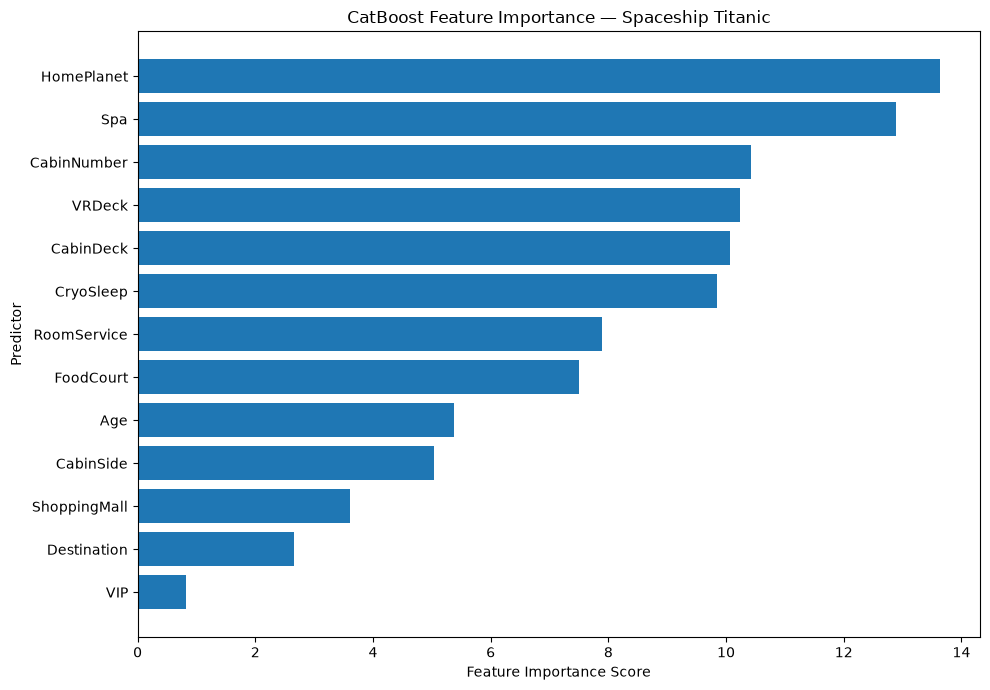

In [27]:
# ============================================================
# STEP 24C: VISUALIZE CATBOOST FEATURE IMPORTANCE
# ============================================================

# Import Matplotlib for visualization.
import matplotlib.pyplot as plt

# Create a horizontal bar chart.
plt.figure(figsize=(10, 7))

# Plot feature importance values.
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

# Display the most important feature at the top.
plt.gca().invert_yaxis()

# Add a chart title.
plt.title(
    "CatBoost Feature Importance — Spaceship Titanic"
)

# Label the horizontal axis.
plt.xlabel("Feature Importance Score")

# Label the vertical axis.
plt.ylabel("Predictor")

# Adjust spacing.
plt.tight_layout()

# Display the chart.
plt.show()

In [28]:
# ============================================================
# STEP 24D: VALIDATE FEATURE IMPORTANCE RESULTS
# ============================================================

# Confirm that every predictor has an importance score.
assert len(feature_importance) == 13, (
    "Unexpected number of importance scores."
)

# Confirm that importance scores are finite.
assert np.isfinite(
    feature_importance["Importance"]
).all(), (
    "Feature importance contains invalid values."
)

# Display the five most important predictors.
print("TOP FIVE CATBOOST FEATURES")
print("-" * 50)

display(
    feature_importance.head(5).round(2)
)

# Display the total importance.
print(
    "Total importance:",
    round(feature_importance["Importance"].sum(), 2)
)

print("\nFeature importance validation completed!")

TOP FIVE CATBOOST FEATURES
--------------------------------------------------


,Feature,Importance
0,HomePlanet,13.63
1,Spa,12.88
2,CabinNumber,10.43
3,VRDeck,10.24
4,CabinDeck,10.07


Total importance: 100.0

Feature importance validation completed!


## Part E — Explain Model Predictions with SHAP (CAT-008)

### 18. Compute SHAP Values for a Reproducible Sample

Use 300 randomly sampled **training** passengers (`random_state=42`) for interpretability. For this binary CatBoost model, the output's first 13 columns are contributions on the raw-score / log-odds scale; its last column is the expected raw prediction value. SHAP explains this fitted model, not causal relationships.

In [29]:
# ============================================================
# STEP 25A: CALCULATE CATBOOST SHAP VALUES
# ============================================================

# Import Pool, which is CatBoost's data container.
from catboost import Pool

# Create a small sample of training observations
# for initial interpretation.
# We use 300 observations to keep the analysis manageable.
shap_sample = X_train_cat.sample(
    n=300,
    random_state=42
)

# Create a CatBoost Pool containing the sample.
shap_pool = Pool(
    data=shap_sample,
    cat_features=categorical_features
)

# Calculate SHAP values using our trained CatBoost model.
shap_values = interpretation_model.get_feature_importance(
    data=shap_pool,
    type="ShapValues"
)

# Display the dimensions of the SHAP output.
print("SHAP values shape:", shap_values.shape)

# Display the number of predictors.
print("Number of predictors:", X_train_cat.shape[1])

SHAP values shape: (300, 14)
Number of predictors: 13


### 19. Mean Absolute SHAP Importance

Mean absolute SHAP summarizes the typical magnitude of a predictor's contribution, without direction. **Observed top five:** Spa (0.7477), CryoSleep (0.6383), VRDeck (0.5822), HomePlanet (0.5515), RoomService (0.5482). This ranking can differ from CatBoost's built-in importance because the definitions differ and this calculation uses a 300-row sample.

In [30]:
# ============================================================
# STEP 25B: CALCULATE MEAN ABSOLUTE SHAP IMPORTANCE
# ============================================================

# Extract feature SHAP values.
# The last column is the expected prediction value,
# so we exclude it.
feature_shap_values = shap_values[:, :-1]

# Calculate mean absolute SHAP values.
mean_absolute_shap = np.abs(
    feature_shap_values
).mean(axis=0)

# Create a DataFrame containing feature importance.
shap_importance = pd.DataFrame({
    "Feature": shap_sample.columns,
    "Mean_Absolute_SHAP": mean_absolute_shap
})

# Sort features from highest to lowest importance.
shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Display the results.
print("MEAN ABSOLUTE SHAP FEATURE IMPORTANCE")
print("-" * 50)

display(shap_importance.round(4))

MEAN ABSOLUTE SHAP FEATURE IMPORTANCE
--------------------------------------------------


,Feature,Mean_Absolute_SHAP
0,Spa,0.7477
1,CryoSleep,0.6383
2,VRDeck,0.5822
3,HomePlanet,0.5515
4,RoomService,0.5482
5,CabinDeck,0.3327
6,CabinSide,0.3176
7,FoodCourt,0.2669
8,CabinNumber,0.2304
9,Destination,0.1537


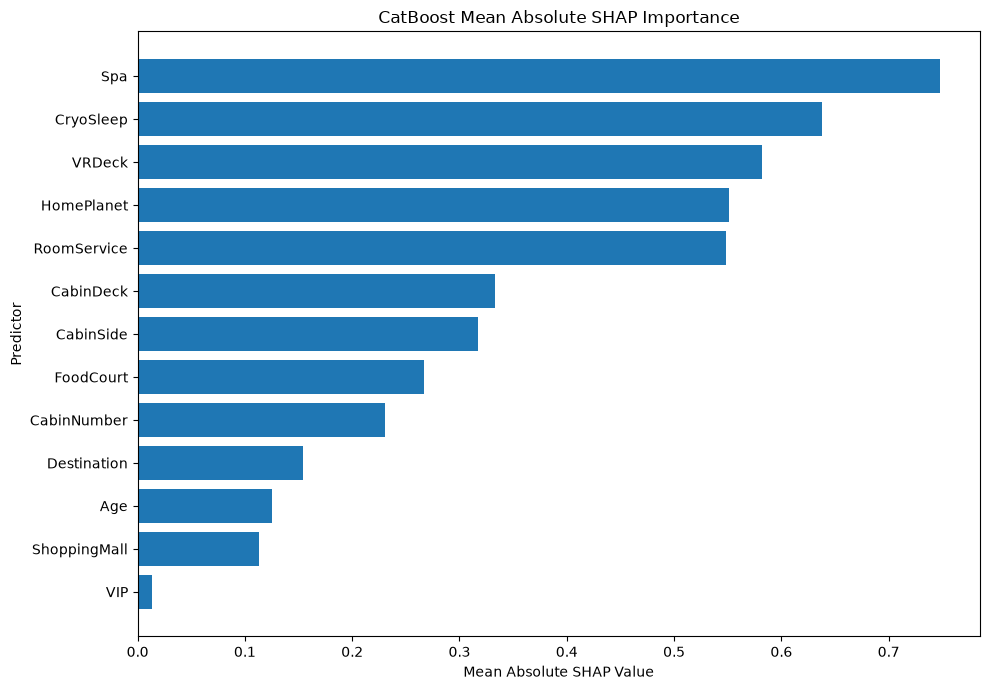

In [31]:
# ============================================================
# STEP 25C: VISUALIZE MEAN ABSOLUTE SHAP IMPORTANCE
# ============================================================

# Create a horizontal bar chart.
plt.figure(figsize=(10, 7))

# Plot mean absolute SHAP values.
plt.barh(
    shap_importance["Feature"],
    shap_importance["Mean_Absolute_SHAP"]
)

# Display the most important feature at the top.
plt.gca().invert_yaxis()

# Add chart title and axis labels.
plt.title(
    "CatBoost Mean Absolute SHAP Importance"
)

plt.xlabel("Mean Absolute SHAP Value")

plt.ylabel("Predictor")

# Adjust chart spacing.
plt.tight_layout()

# Display the chart.
plt.show()

### 20. Signed SHAP — Spa

Signed SHAP values show whether Spa pushes a passenger's prediction **toward** (`> 0`) or **away from** (`< 0`) `Transported=True` on the log-odds scale. In this sample, the mean signed Spa contribution was approximately **−0.0765**, despite a much larger mean absolute importance. Missing Spa amounts are treated as missing rather than assumed to be zero.

In [32]:
# ============================================================
# STEP 26A: EXAMINE SPA SPENDING AND SHAP CONTRIBUTIONS
# ============================================================

# Find the position of Spa among our model predictors.
spa_index = shap_sample.columns.get_loc("Spa")

# Extract Spa SHAP values from the 300 sampled passengers.
spa_shap_values = feature_shap_values[:, spa_index]

# Create a DataFrame containing Spa spending
# and its corresponding SHAP contribution.
spa_analysis = pd.DataFrame({
    "Spa": shap_sample["Spa"].to_numpy(),
    "Spa_SHAP": spa_shap_values
})

# Display the first ten observations.
print("SPA SPENDING AND SHAP CONTRIBUTIONS")
print("-" * 50)

display(spa_analysis.head(10))

# Calculate the average signed SHAP contribution.
print(
    "\nMean signed Spa SHAP:",
    round(spa_analysis["Spa_SHAP"].mean(), 4)
)

SPA SPENDING AND SHAP CONTRIBUTIONS
--------------------------------------------------


,Spa,Spa_SHAP
0,0.0,0.459679
1,0.0,0.521481
2,0.0,0.437352
3,0.0,0.363084
4,0.0,0.579707
5,36.0,0.310717
6,340.0,-0.776967
7,NaN,0.348584
8,0.0,0.366014
9,0.0,0.493836



Mean signed Spa SHAP: -0.0765


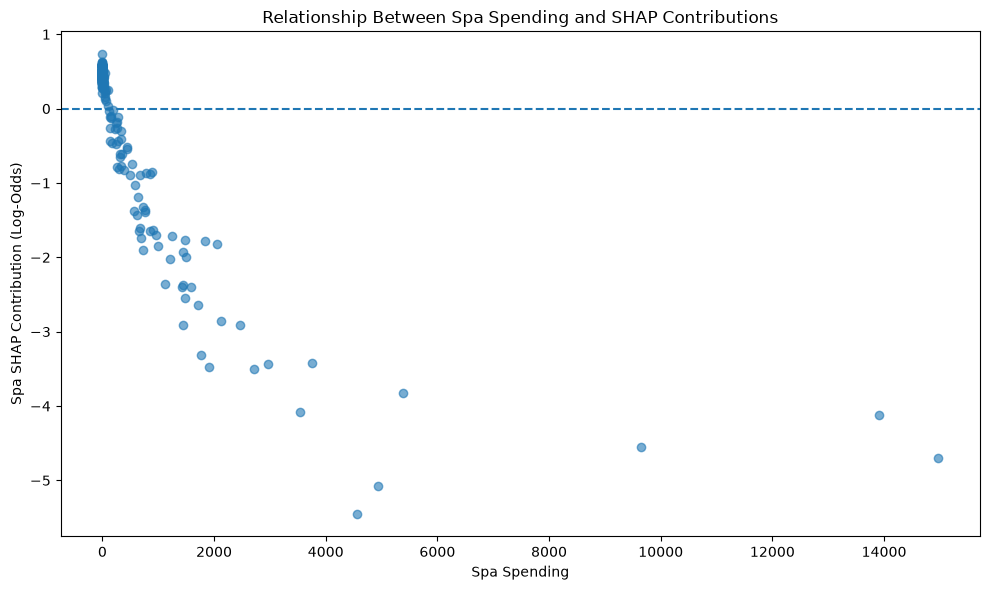

In [33]:
# ============================================================
# STEP 26B: VISUALIZE SPA SHAP CONTRIBUTIONS
# ============================================================

# Create a scatter plot of Spa spending against
# the model's SHAP contribution from Spa.
plt.figure(figsize=(10, 6))

plt.scatter(
    spa_analysis["Spa"],
    spa_analysis["Spa_SHAP"],
    alpha=0.6
)

# Draw a horizontal line representing zero contribution.
plt.axhline(
    y=0,
    linestyle="--"
)

# Add labels and title.
plt.xlabel("Spa Spending")

plt.ylabel("Spa SHAP Contribution (Log-Odds)")

plt.title(
    "Relationship Between Spa Spending and SHAP Contributions"
)

# Adjust chart spacing.
plt.tight_layout()

# Display the chart.
plt.show()

### 21. Signed SHAP — CryoSleep

Sample mean SHAP contributions were approximately **+0.8824** for `CryoSleep=True` (n=107), **−0.5109** for `False` (n=184), and **−0.3411** for `Missing` (n=9). This is consistent with earlier exploratory associations, but SHAP explains model predictions—not causal effects. The missing category sample is particularly small.

In [34]:
# ============================================================
# STEP 26C: EXAMINE CRYOSLEEP SHAP CONTRIBUTIONS
# ============================================================

# Find CryoSleep's position among the model predictors.
cryo_index = shap_sample.columns.get_loc("CryoSleep")

# Extract SHAP contributions for CryoSleep.
cryo_shap_values = feature_shap_values[:, cryo_index]

# Create a DataFrame containing CryoSleep and its
# corresponding SHAP contribution.
cryo_analysis = pd.DataFrame({
    "CryoSleep": shap_sample["CryoSleep"].to_numpy(),
    "CryoSleep_SHAP": cryo_shap_values
})

# Calculate descriptive statistics by CryoSleep category.
cryo_summary = (
    cryo_analysis
    .groupby("CryoSleep")["CryoSleep_SHAP"]
    .agg(["count", "mean", "median", "std"])
)

# Display the results.
print("CRYOSLEEP SHAP CONTRIBUTIONS")
print("-" * 50)

display(cryo_summary.round(4))

CRYOSLEEP SHAP CONTRIBUTIONS
--------------------------------------------------


,count,mean,median,std
CryoSleep,,,,
False,184,-0.5109,-0.4861,0.1240
Missing,9,-0.3411,-0.3184,0.1175
True,107,0.8824,0.9324,0.2432


## Summary and Decision

| Experiment | Question | Development finding |
|---|---|---|
| CAT-003 | Do passenger-group features help? | 80.33% mean stratified CV; lower than baseline |
| CAT-004 | Does tree depth improve performance? | Depth 6 best among tested depths |
| CAT-005 | Do learning rate / iterations improve performance? | Baseline 0.05 / 500 best among tested settings |
| CAT-006 | Does group separation change evaluation? | 80.85% mean group-aware CV, with more fold variation |
| CAT-007 | What drives built-in importance? | HomePlanet highest |
| CAT-008 | What drives average prediction contributions? | Spa highest by mean absolute SHAP |

**Selected model:** CatBoost with 13 original predictors, depth 6, learning rate 0.05, 500 iterations. Historical mean stratified CV accuracy **81.12%**; Kaggle public leaderboard accuracy **80.383%** (from the separate submission exercise).

**Limitations:** Reported CV scores were used repeatedly for feature and hyperparameter comparisons, so they are not fully independent post-selection estimates. The earlier holdout was also inspected during development. The 300-row SHAP sample describes fitted-model behavior rather than causality. GroupSize uses identifiers from the unlabeled Kaggle test manifest and relies on full-manifest availability. The notebook has retained saved outputs, but those outputs are **not** proof of a fresh clean-kernel run.

**Portfolio next step:** Run the notebook from a restarted kernel with `train.csv` and `test.csv` available, verify outputs, and only then publish it alongside the other reviewed notebooks.

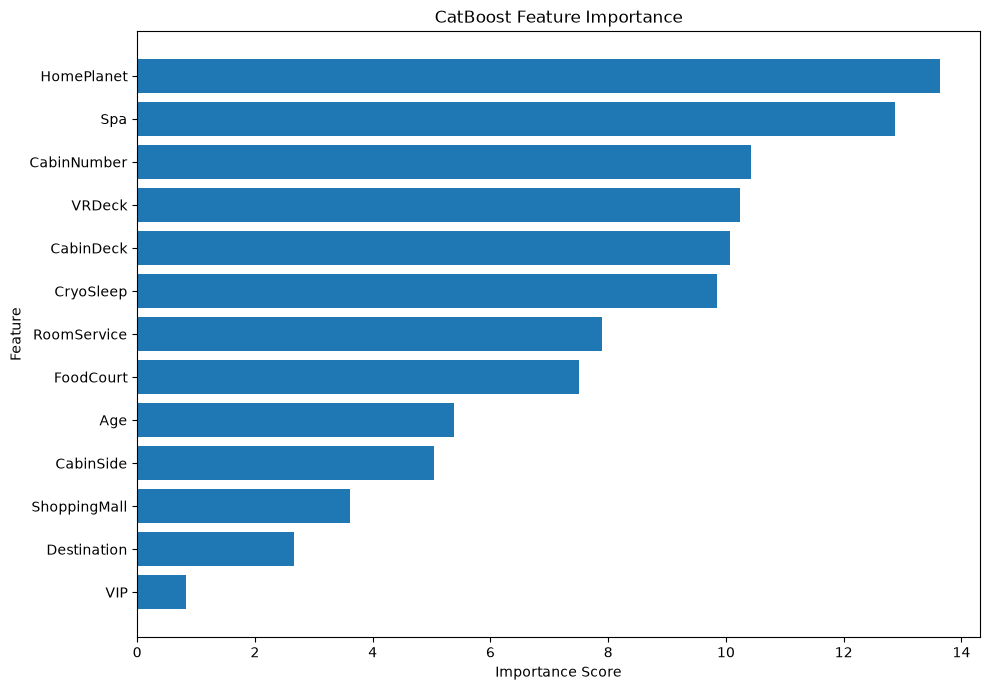

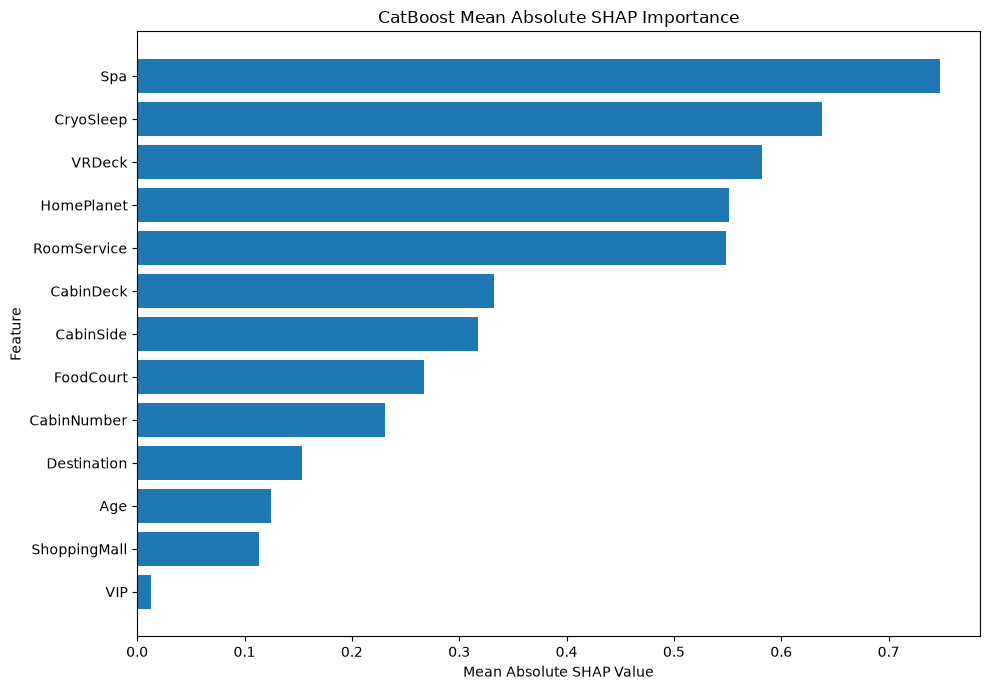

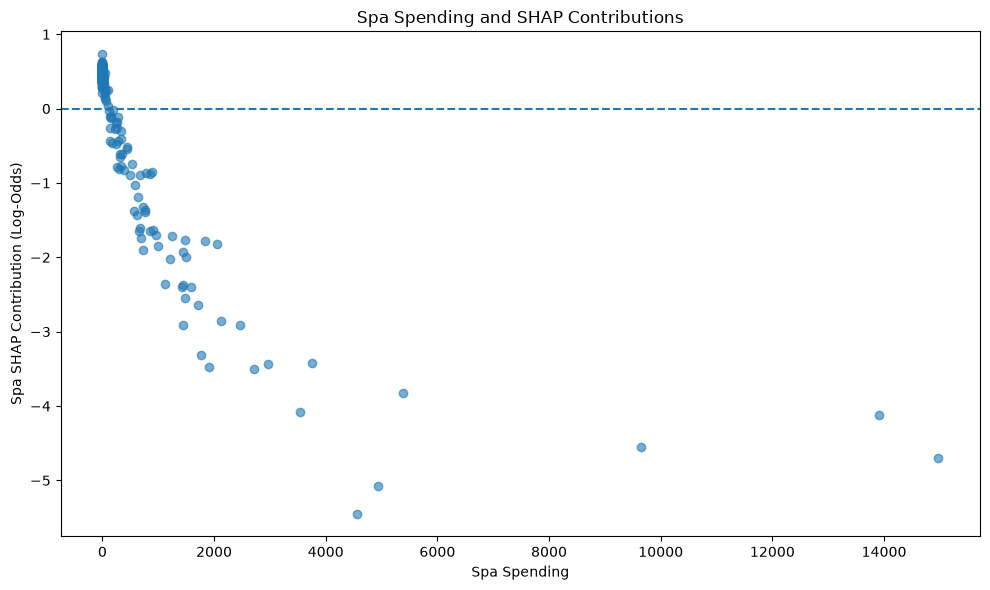


FIGURES SAVED SUCCESSFULLY
--------------------------------------------------
catboost_feature_importance.png
shap_feature_importance.png
spa_shap_analysis.png


In [35]:
# ============================================================
# EXPORT IMPORTANT MODEL VISUALIZATIONS
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

# Identify the main project directory.
# The notebook is located inside the "notebooks" folder.
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Create the figures directory if it does not exist.
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# FIGURE 1: CATBOOST FEATURE IMPORTANCE
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("CatBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()

# Save the figure.
plt.savefig(
    figures_dir / "catboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# FIGURE 2: SHAP FEATURE IMPORTANCE
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.barh(
    shap_importance["Feature"],
    shap_importance["Mean_Absolute_SHAP"]
)

plt.gca().invert_yaxis()

plt.title("CatBoost Mean Absolute SHAP Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    figures_dir / "shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# FIGURE 3: SPA SHAP ANALYSIS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    spa_analysis["Spa"],
    spa_analysis["Spa_SHAP"],
    alpha=0.6
)

# Draw a reference line at zero contribution.
plt.axhline(y=0, linestyle="--")

plt.title("Spa Spending and SHAP Contributions")
plt.xlabel("Spa Spending")
plt.ylabel("Spa SHAP Contribution (Log-Odds)")

plt.tight_layout()

plt.savefig(
    figures_dir / "spa_shap_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# VERIFY SAVED FILES
# ------------------------------------------------------------

print("\nFIGURES SAVED SUCCESSFULLY")
print("-" * 50)

for figure_file in sorted(figures_dir.glob("*.png")):
    print(figure_file.name)